# C23 — Laboratório de Inteligência Artificial
## Aula 03: Regressão

**Objetivo da aula:** compreender como modelos de regressão aprendem relações entre atributos e uma variável-alvo contínua, avaliar sua capacidade de generalização e comparar diferentes estratégias de modelagem.

Nesta aula, vamos partir de um problema real, construir modelos de regressão e observar na prática os efeitos da complexidade, do sobreajuste e da regularização.

# 1. Conceitos Fundamentais

## 1.1 O que é regressão?

Regressão é uma tarefa de aprendizado supervisionado na qual o modelo aprende uma função para estimar uma **variável-alvo quantitativa** a partir de um ou mais atributos.

Em termos gerais:

**atributos de entrada → modelo → valor numérico previsto**

Exemplos de aplicações:

- estimar preços de imóveis;
- prever consumo de energia;
- estimar demanda de produtos;
- prever tempo de processamento;
- estimar indicadores clínicos ou biológicos.

## 1.2 Função hipótese e erro

Na regressão linear, uma função hipótese pode ser representada por:

**ŷ = θ₀ + θ₁x₁ + θ₂x₂ + ... + θₖxₖ**

Os parâmetros θ são os pesos aprendidos pelo modelo.

A diferença entre o valor real `y` e o valor previsto `ŷ` é chamada de **erro ou resíduo**:

**erro = y − ŷ**

Uma das funções de erro mais utilizadas é o Erro Quadrático Médio (EQM ou MSE):

**MSE = (1/N) Σ(yᵢ − ŷᵢ)²**

O treinamento procura encontrar os pesos que minimizam essa função de erro.

## 1.3 Como encontrar os pesos?

### Gradiente descendente

É uma abordagem iterativa. A cada passo, os pesos são atualizados na direção que reduz a função de erro.

**Ideia central:**

1. iniciar os pesos;
2. calcular as previsões;
3. calcular o erro;
4. calcular o gradiente;
5. atualizar os pesos;
6. repetir até a convergência.

O gradiente descendente é especialmente importante porque a mesma ideia aparece em diversos algoritmos de aprendizado de máquina e redes neurais.

## 1.4 Regressão polinomial e complexidade

Uma relação entre as variáveis nem sempre é bem representada por uma reta.

Podemos criar novos atributos a partir de potências dos atributos originais. Por exemplo:

**ŷ = θ₀ + θ₁x + θ₂x² + θ₃x³ + ...**

Aumentar o grau do polinômio aumenta a **flexibilidade** do modelo.

Essa flexibilidade pode ser útil, mas também pode produzir:

- **Underfitting:** modelo simples demais para representar o padrão dos dados;
- **Ajuste adequado:** modelo suficientemente flexível para capturar o padrão e generalizar;
- **Overfitting:** modelo complexo demais, que passa a se ajustar excessivamente aos dados de treinamento.

A escolha do modelo deve considerar não apenas o erro de treinamento, mas principalmente sua capacidade de generalização.

## 1.5 Validação cruzada

A validação cruzada permite avaliar diferentes modelos ou hiperparâmetros utilizando diferentes divisões dos dados de treinamento.

Ela pode ser utilizada para:

- comparar modelos;
- escolher a complexidade de um modelo;
- ajustar hiperparâmetros;
- estimar a capacidade de generalização.

Na regressão polinomial, por exemplo, podemos testar diferentes graus e escolher aquele que apresenta melhor desempenho de validação, evitando simplesmente escolher o modelo com menor erro de treinamento.

## 1.6 Regularização

Outra estratégia para controlar a complexidade é a **regularização**.

A ideia é penalizar modelos que utilizam pesos excessivamente grandes.

### Ridge — regularização L2

Adiciona uma penalização proporcional à soma dos quadrados dos pesos.

A Ridge tende a manter todos os atributos no modelo, reduzindo a magnitude de seus pesos.

### LASSO — regularização L1

Adiciona uma penalização proporcional à soma dos valores absolutos dos pesos.

Uma consequência importante é que alguns pesos podem chegar a zero, realizando uma forma de **seleção automática de atributos**.

### Elastic-Net

Combina as penalizações L1 e L2.

É especialmente útil quando queremos combinar as características de Ridge e LASSO, por exemplo em situações com atributos correlacionados.

## 1.7 Métricas de avaliação

Para avaliar um modelo de regressão, podemos utilizar diferentes métricas. Cada uma responde a uma pergunta diferente sobre a qualidade das previsões.

### MAE — Erro Absoluto Médio

**MAE = (1/N) Σ|yᵢ − ŷᵢ|**

O MAE representa o **erro absoluto médio das previsões**. Em outras palavras, indica **quanto, em média, a previsão se afasta do valor real**.

**Como interpretar:**

- **MAE = 0:** todas as previsões são exatamente iguais aos valores reais.
- **MAE pequeno:** as previsões estão, em média, próximas dos valores reais.
- **MAE grande:** as previsões apresentam erros maiores.

**Intervalo de valores:**  
`0 ≤ MAE < ∞`

O MAE **não possui um valor máximo fixo**. Seu limite depende da escala da variável-alvo.

**Valor ideal:** **0**

Uma característica importante é que o MAE trata os erros de maneira **linear**: um erro de 10 possui duas vezes o impacto de um erro de 5.

---

### MSE — Erro Quadrático Médio

**MSE = (1/N) Σ(yᵢ − ŷᵢ)²**

O MSE calcula a média dos **erros ao quadrado**.

O objetivo é semelhante ao MAE, mas existe uma diferença importante: **erros grandes recebem uma penalização muito maior**.

Por exemplo:

- erro = 2 → erro² = 4
- erro = 5 → erro² = 25
- erro = 10 → erro² = 100

Assim, o MSE dá muito mais importância às previsões que apresentam erros elevados.

**Como interpretar:**

- **MSE = 0:** previsões perfeitas.
- **MSE pequeno:** erros pequenos.
- **MSE grande:** presença de erros maiores, especialmente erros extremos.

**Intervalo de valores:**  
`0 ≤ MSE < ∞`

**Valor ideal:** **0**

Uma desvantagem para a interpretação é que o MSE fica em **unidade ao quadrado**. Se a variável-alvo está em reais, por exemplo, o MSE estará em reais².

---

### RMSE — Raiz do Erro Quadrático Médio

**RMSE = √MSE**

O RMSE é obtido calculando a raiz quadrada do MSE. Isso faz com que ele volte para a **mesma unidade da variável-alvo**.

Sua interpretação é semelhante à do MAE:

> **O RMSE indica a magnitude típica dos erros de previsão, dando maior peso aos erros grandes.**

**Como interpretar:**

- **RMSE = 0:** previsões perfeitas.
- **RMSE pequeno:** previsões próximas dos valores reais.
- **RMSE grande:** erros de previsão maiores.
- Se o **RMSE estiver muito acima do MAE**, isso pode indicar a presença de alguns erros particularmente grandes.

**Intervalo de valores:**  
`0 ≤ RMSE < ∞`

**Valor ideal:** **0**

Por exemplo, se estamos prevendo preços de imóveis e obtemos:

> **RMSE = R$ 25.000**

podemos interpretar que os erros de previsão têm uma magnitude típica de aproximadamente **R$ 25 mil**, com os erros grandes tendo maior influência no resultado.

---

### R² — Coeficiente de determinação

O R² mede **quanto da variabilidade da variável-alvo é explicada pelo modelo**, comparando-o com um modelo de referência que simplesmente prevê a média dos valores.

Uma forma intuitiva de interpretar é:

> **R² responde: "Quanto o modelo consegue explicar sobre a variação dos dados?"**

**Como interpretar:**

- **R² = 1:** o modelo explica 100% da variabilidade observada.
- **R² = 0:** o modelo não é melhor que simplesmente prever a média.
- **R² > 0:** o modelo explica parte da variabilidade e supera a referência da média.
- **R² < 0:** o modelo apresenta desempenho pior que simplesmente utilizar a média como previsão.

**Intervalo de valores:**  
`−∞ < R² ≤ 1`

O limite superior é **1**, mas não existe um limite inferior fixo.

**Valor ideal:** **1**

Por exemplo:

> **R² = 0,80**

significa que o modelo explica aproximadamente **80% da variabilidade observada na variável-alvo**, em relação à previsão pela média.

> **Importante:** R² = 0,80 não significa que o modelo "acerta 80% das previsões". Ele mede a **variabilidade explicada**, não uma porcentagem de acertos.

---

### Comparação rápida

| Métrica | O que responde? | Intervalo | Ideal | Penaliza erros grandes? |
|---|---|---:|---:|---|
| **MAE** | Quanto erramos, em média? | 0 → ∞ | **0** | Não |
| **MSE** | Quanto erramos, dando muito peso aos erros grandes? | 0 → ∞ | **0** | **Sim** |
| **RMSE** | Qual a magnitude típica dos erros, dando peso aos erros grandes? | 0 → ∞ | **0** | **Sim** |
| **R²** | Quanto da variabilidade conseguimos explicar? | −∞ → 1 | **1** | — |

### Atenção à interpretação

Não existe uma regra universal como **"MAE abaixo de 10 é bom"** ou **"R² acima de 0,8 é bom"**.

O valor precisa ser analisado **no contexto do problema**, considerando principalmente a escala da variável-alvo e o impacto dos erros na aplicação.

Por exemplo, um **RMSE = 5** pode ser excelente se estivermos prevendo uma variável que varia entre 0 e 100, mas pode ser péssimo se a variável varia apenas entre 0 e 10.

**Em resumo:**

> **MAE, MSE e RMSE → quanto menor, melhor.**  
> **R² → quanto maior, melhor.**  
> **Mas o que é "bom" depende do problema, da escala da variável e do impacto dos erros.**

Nenhuma métrica deve ser analisada isoladamente. O contexto do problema determina qual aspecto do erro é mais relevante.

## 1.8 Limitações e boas práticas

Um modelo de regressão pode apresentar bom desempenho aparente e ainda assim não generalizar.

Por isso:

- separe treinamento e teste antes de avaliar o modelo;
- não use o conjunto de teste para escolher hiperparâmetros;
- faça o pré-processamento utilizando apenas informações disponíveis no treinamento;
- utilize validação cruzada para comparar modelos e ajustar hiperparâmetros;
- não confunda correlação com causalidade;
- considere o contexto da aplicação antes de interpretar os pesos;
- prefira modelos suficientemente simples quando modelos mais complexos não oferecem ganho de generalização.

**Ideia central:** o melhor modelo não é necessariamente o que melhor se ajusta aos dados de treinamento, mas aquele que apresenta boa capacidade de generalização.

## Referências

- GÉRON, A. *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*. O'Reilly Media, 2022.
- JAMES, G.; WITTEN, D.; HASTIE, T.; TIBSHIRANI, R. *An Introduction to Statistical Learning*. 2. ed. Springer, 2021.
- MCKINNEY, W. *Python for Data Analysis*. 3. ed. O'Reilly Media, 2022.
- PEDREGOSA, F. et al. Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, v. 12, p. 2825–2830, 2011.

# 2. Prática Guiada

Nesta etapa, vamos construir modelos de regressão utilizando um conjunto de dados real.

O conjunto **Diabetes**, disponibilizado pelo scikit-learn, contém 442 amostras e 10 atributos relacionados a características fisiológicas dos pacientes. A variável-alvo representa uma medida quantitativa da progressão da doença um ano após a linha de base.

Vamos estudar:

1. preparação dos dados;
2. regressão linear;
3. avaliação por diferentes métricas;
4. gradiente descendente em um problema simples;
5. regressão polinomial;
6. underfitting e overfitting;
7. validação cruzada;
8. Ridge, LASSO e Elastic-Net.

In [1]:
# Bibliotecas utilizadas nesta prática.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [22]:
# Carregamos o conjunto de dados Diabetes.
diabetes = load_diabetes(as_frame=True)

X = diabetes.data
y = diabetes.target

df = pd.concat([X, y.rename("target")], axis=1)

print(f"Amostras: {df.shape[0]}")
print(f"Atributos: {X.shape[1]}")

print("\nAtributos e seus significados:")
print("- age: idade do paciente.")
print("- sex: sexo do paciente.")
print("- bmi: índice de massa corporal (IMC).")
print("- bp: pressão arterial média.")
print("- s1: medida relacionada ao colesterol total.")
print("- s2: medida relacionada à lipoproteína de baixa densidade (LDL).")
print("- s3: medida relacionada à lipoproteína de alta densidade (HDL).")
print("- s4: medida relacionada à razão entre colesterol total e HDL.")
print("- s5: medida relacionada à triglicerídeos.")
print("- s6: medida relacionada à glicemia.")
print("- target: medida quantitativa da progressão da doença após um ano.")

print("\nNomes dos atributos:")
print(X.columns.tolist())

print("\nPrimeiras amostras:")
display(df.head())

print("\nEstatísticas descritivas dos atributos:")
display(X.describe().round(4))

# Os valores dos atributos estão em uma escala reduzida e, em geral, distribuídos em torno de **zero**.
# Isso ocorre porque o conjunto `Diabetes` disponibilizado pelo `scikit-learn` já fornece os atributos pré-processados.
# Isso significa que, para esta atividade, não precisamos realizar conversão de variáveis categóricas ou normalização dos atributos antes de treinar os modelos.
# Atenção: estar numericamente preparado não significa que o conjunto de dados esteja "pronto para qualquer modelo".
# Em um problema real, ainda devemos investigar valores ausentes, outliers, distribuição dos dados, correlação entre atributos e possíveis problemas de escala.


Amostras: 442
Atributos: 10

Atributos e seus significados:
- age: idade do paciente.
- sex: sexo do paciente.
- bmi: índice de massa corporal (IMC).
- bp: pressão arterial média.
- s1: medida relacionada ao colesterol total.
- s2: medida relacionada à lipoproteína de baixa densidade (LDL).
- s3: medida relacionada à lipoproteína de alta densidade (HDL).
- s4: medida relacionada à razão entre colesterol total e HDL.
- s5: medida relacionada à triglicerídeos.
- s6: medida relacionada à glicemia.
- target: medida quantitativa da progressão da doença após um ano.

Nomes dos atributos:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Primeiras amostras:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



Estatísticas descritivas dos atributos:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000
mean,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000
std,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476
min,-0.1072,-0.0446,-0.0903,-0.1124,-0.1268,-0.1156,-0.1023,-0.0764,-0.1261,-0.1378
25%,-0.0373,-0.0446,-0.0342,-0.0367,-0.0342,-0.0304,-0.0351,-0.0395,-0.0332,-0.0332
50%,0.0054,-0.0446,-0.0073,-0.0057,-0.0043,-0.0038,-0.0066,-0.0026,-0.0019,-0.0011
75%,0.0381,0.0507,0.0312,0.0356,0.0284,0.0298,0.0293,0.0343,0.0324,0.0279
max,0.1107,0.0507,0.1706,0.1320,0.1539,0.1988,0.1812,0.1852,0.1336,0.1356


### Conhecendo o problema

A variável `target` é quantitativa e representa uma medida de progressão da doença. Portanto, estamos diante de um **problema de regressão**.

In [3]:
# Separação entre dados de treinamento e teste.
# O conjunto de teste será preservado para a avaliação final.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Treinamento: {X_train.shape[0]} amostras")
print(f"Teste: {X_test.shape[0]} amostras")

Treinamento: 353 amostras
Teste: 89 amostras


## 2.1 Construindo uma regressão linear

Vamos começar com uma regressão linear múltipla.

O fluxo básico será:

**dados → treinamento → previsão → avaliação**

In [23]:
# Criamos e treinamos o modelo de regressão linear.
modelo_linear = LinearRegression()
modelo_linear.fit(X_train, y_train)

# O modelo aprende uma equação no formato:
# ŷ = intercepto + (peso₁ × atributo₁) + (peso₂ × atributo₂) + ...

# Fazemos previsões para os dados de teste.
y_pred = modelo_linear.predict(X_test)

# O intercepto (β₀) é o valor previsto quando todos os atributos são zero.
print(f"Intercepto (β₀): {modelo_linear.intercept_:.2f}")

# Os pesos (β₁, β₂, ...) indicam quanto a previsão tende a variar
# quando o respectivo atributo aumenta uma unidade,
# mantendo os demais atributos constantes.
pesos = pd.Series(modelo_linear.coef_, index=X.columns)

print("\nPesos (coeficientes):")
display(pesos.sort_values(ascending=False).to_frame("coeficiente"))

# Para facilitar a interpretação, mostramos também a magnitude dos coeficientes.
# Quanto maior o valor absoluto, maior é a contribuição linear do atributo
# na equação, considerando a escala em que os dados estão representados.
print("\nCoeficientes em ordem de magnitude:")
display(
    pesos.abs()
    .sort_values(ascending=False)
    .to_frame("|coeficiente|")
)

Intercepto (β₀): 151.35

Pesos (coeficientes):


,coeficiente
s5,736.198859
bmi,542.428759
s2,518.062277
bp,347.703844
s4,275.317902
s3,163.419983
s6,48.670657
age,37.904021
sex,-241.964362
s1,-931.488846



Coeficientes em ordem de magnitude:


,|coeficiente|
s1,931.488846
s5,736.198859
bmi,542.428759
s2,518.062277
bp,347.703844
s4,275.317902
sex,241.964362
s3,163.419983
s6,48.670657
age,37.904021


In [5]:
# Função auxiliar para calcular as principais métricas de regressão.
def avaliar_regressao(y_real, y_previsto):
    mae = mean_absolute_error(y_real, y_previsto)
    mse = mean_squared_error(y_real, y_previsto)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_real, y_previsto)

    return pd.Series({
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2
    })

avaliar_regressao(y_test, y_pred)

,0
MAE,42.794095
MSE,2900.193628
RMSE,53.853446
R²,0.452603


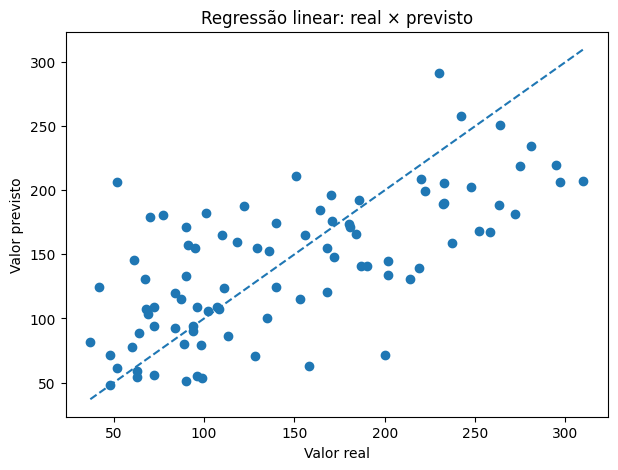

In [6]:
# Comparação visual entre os valores reais e previstos.
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)

limite_min = min(y_test.min(), y_pred.min())
limite_max = max(y_test.max(), y_pred.max())

plt.plot([limite_min, limite_max], [limite_min, limite_max], "--")
plt.xlabel("Valor real")
plt.ylabel("Valor previsto")
plt.title("Regressão linear: real × previsto")
plt.show()

## 2.2 Observando o gradiente descendente

A teoria mostrou que o gradiente descendente encontra os pesos iterativamente.

Para visualizar essa ideia, vamos trabalhar com um único atributo: `bmi`.

A implementação a seguir é didática. Em problemas reais, bibliotecas especializadas são preferíveis.

In [8]:
# Regressão linear simples implementada com gradiente descendente.
X_bmi = X_train[["bmi"]].to_numpy()
y_bmi = y_train.to_numpy()

theta_0 = 0.0
theta_1 = 0.0

learning_rate = 0.05
n_iteracoes = 1000

historico_erro = []

for _ in range(n_iteracoes):
    y_hat = theta_0 + theta_1 * X_bmi[:, 0]
    erro = y_hat - y_bmi

    grad_theta_0 = (2 / len(y_bmi)) * np.sum(erro)
    grad_theta_1 = (2 / len(y_bmi)) * np.sum(erro * X_bmi[:, 0])

    theta_0 -= learning_rate * grad_theta_0
    theta_1 -= learning_rate * grad_theta_1

    historico_erro.append(np.mean(erro ** 2))

print(f"θ₀ = {theta_0:.4f}")
print(f"θ₁ = {theta_1:.4f}")

θ₀ = 153.3930
θ₁ = 199.7239


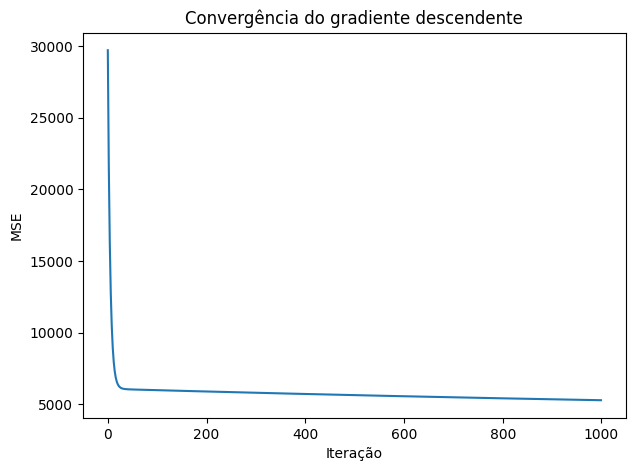

In [9]:
# Evolução da função de erro durante o treinamento.
plt.figure(figsize=(7, 5))
plt.plot(historico_erro)
plt.xlabel("Iteração")
plt.ylabel("MSE")
plt.title("Convergência do gradiente descendente")
plt.show()

### Observe

O erro tende a diminuir ao longo das iterações.

O comportamento depende de fatores como valores iniciais dos pesos, taxa de aprendizagem, quantidade de iterações e escala dos atributos.

Uma taxa de aprendizagem inadequada pode tornar o treinamento muito lento ou até impedir a convergência.

## 2.3 Regressão polinomial

Agora vamos investigar o efeito da complexidade.

Usaremos novamente apenas `bmi`, mas criaremos modelos polinomiais com diferentes graus.

A pergunta não será:

> Qual modelo apresenta menor erro de treinamento?

A pergunta será:

> Qual complexidade apresenta melhor capacidade de generalização?

In [10]:
# Comparação de diferentes graus polinomiais.
X_train_bmi = X_train[["bmi"]]
X_test_bmi = X_test[["bmi"]]

graus = [1, 2, 3, 5, 10, 15]
resultados = []

for grau in graus:
    modelo = Pipeline([
        ("polinomio", PolynomialFeatures(degree=grau, include_bias=False)),
        ("regressao", LinearRegression())
    ])

    modelo.fit(X_train_bmi, y_train)

    pred_train = modelo.predict(X_train_bmi)
    pred_test = modelo.predict(X_test_bmi)

    resultados.append({
        "grau": grau,
        "MSE treinamento": mean_squared_error(y_train, pred_train),
        "MSE teste": mean_squared_error(y_test, pred_test),
        "R² treinamento": r2_score(y_train, pred_train),
        "R² teste": r2_score(y_test, pred_test)
    })

resultados_graus = pd.DataFrame(resultados)
resultados_graus

,grau,MSE treinamento,MSE teste,R² treinamento,R² teste
0,1,3854.112652,4061.825928,0.365724,0.233350
1,2,3849.333133,4085.025481,0.366511,0.228972
2,3,3848.447238,4064.443384,0.366656,0.232856
3,5,3823.763813,4085.845567,0.370719,0.228817
4,10,3724.612687,4315.533060,0.387036,0.185464
5,15,3708.122534,30391.328894,0.389750,-4.736213


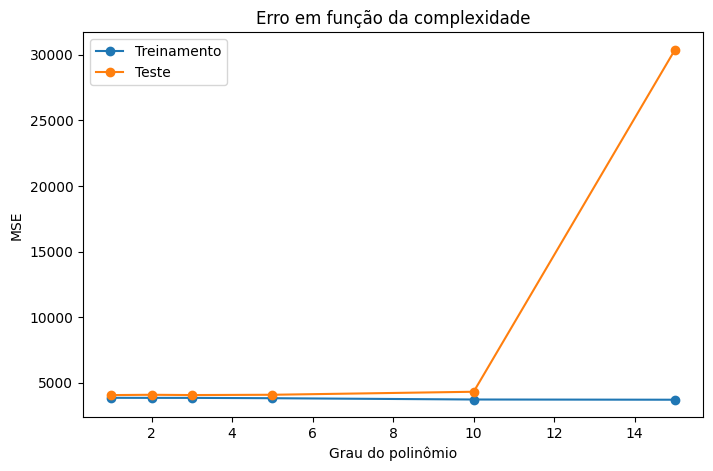

In [11]:
# Visualização do efeito da complexidade.
plt.figure(figsize=(8, 5))
plt.plot(resultados_graus["grau"], resultados_graus["MSE treinamento"],
         marker="o", label="Treinamento")
plt.plot(resultados_graus["grau"], resultados_graus["MSE teste"],
         marker="o", label="Teste")
plt.xlabel("Grau do polinômio")
plt.ylabel("MSE")
plt.title("Erro em função da complexidade")
plt.legend()
plt.show()

### Interpretando underfitting e overfitting

Observe a relação entre os erros de treinamento e teste.

- **Underfitting:** modelo simples demais, com erro alto também nos dados de treinamento.
- **Ajuste adequado:** boa representação do padrão com desempenho semelhante em dados inéditos.
- **Overfitting:** o erro de treinamento continua baixo, enquanto o desempenho em dados inéditos piora.

A escolha do grau deve buscar um equilíbrio entre flexibilidade e generalização.

## 2.4 Validação cruzada

Usar apenas uma divisão entre treinamento e teste pode fazer com que a comparação dependa daquela divisão específica.

Vamos utilizar validação cruzada com 5 partições para comparar os graus polinomiais.

O conjunto de teste continuará separado e será utilizado somente na avaliação final.

In [12]:
# Validação cruzada no conjunto de treinamento.
kf = KFold(n_splits=5, shuffle=True, random_state=42)

resultados_cv = []

for grau in graus:
    modelo = Pipeline([
        ("polinomio", PolynomialFeatures(degree=grau, include_bias=False)),
        ("regressao", LinearRegression())
    ])

    scores = cross_val_score(
        modelo, X_train_bmi, y_train,
        cv=kf, scoring="neg_mean_squared_error"
    )

    resultados_cv.append({
        "grau": grau,
        "MSE médio na validação cruzada": -scores.mean(),
        "desvio padrão": scores.std()
    })

resultados_cv = pd.DataFrame(resultados_cv)
resultados_cv

,grau,MSE médio na validação cruzada,desvio padrão
0,1,3909.151329,212.711988
1,2,3937.031818,196.177403
2,3,3953.648426,185.399418
3,5,3967.435917,223.860651
4,10,74343.420179,140581.467882
5,15,85378.925457,162634.046119


In [13]:
melhor_grau = resultados_cv.loc[
    resultados_cv["MSE médio na validação cruzada"].idxmin(), "grau"
]

print(f"Melhor grau entre os testados: {int(melhor_grau)}")

Melhor grau entre os testados: 1


In [14]:
# Treinamos novamente o modelo escolhido usando todo o conjunto de treinamento.
modelo_polinomial = Pipeline([
    ("polinomio", PolynomialFeatures(degree=int(melhor_grau), include_bias=False)),
    ("regressao", LinearRegression())
])

modelo_polinomial.fit(X_train_bmi, y_train)
pred_polinomial = modelo_polinomial.predict(X_test_bmi)

avaliar_regressao(y_test, pred_polinomial)

,0
MAE,52.259976
MSE,4061.825928
RMSE,63.732456
R²,0.233350


## 2.5 Regularização: Ridge, LASSO e Elastic-Net

Agora voltamos ao problema multivariado, utilizando os 10 atributos.

A regularização adiciona uma penalização ao treinamento para controlar a magnitude dos pesos.

Vamos comparar:

- regressão linear;
- Ridge;
- LASSO;
- Elastic-Net.

Como Ridge, LASSO e Elastic-Net são sensíveis à escala dos atributos, utilizaremos `StandardScaler` dentro de um `Pipeline`. Assim, o escalonamento é aprendido corretamente a partir dos dados usados no treinamento.

In [15]:
# Modelos regularizados.
modelos = {
    "Linear": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", Ridge(alpha=1.0))
    ]),
    "LASSO": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", Lasso(alpha=0.1, max_iter=10000))
    ]),
    "Elastic-Net": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000))
    ])
}

resultados_modelos = []

for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    metricas = avaliar_regressao(y_test, pred)

    resultados_modelos.append({
        "Modelo": nome,
        **metricas.to_dict()
    })

comparacao = pd.DataFrame(resultados_modelos)
comparacao

,Modelo,MAE,MSE,RMSE,R²
0,Linear,42.794095,2900.193628,53.853446,0.452603
1,Ridge,42.811999,2892.014566,53.777454,0.454147
2,LASSO,42.805234,2884.624289,53.708698,0.455541
3,Elastic-Net,42.873332,2866.461255,53.539343,0.458970


In [16]:
# Comparação dos pesos dos modelos regularizados.
pesos = pd.DataFrame(index=X.columns)

for nome in ["Ridge", "LASSO", "Elastic-Net"]:
    pesos[nome] = modelos[nome].named_steps["modelo"].coef_

pesos

,Ridge,LASSO,Elastic-Net
age,1.807342,1.730451,1.901571
sex,-11.448190,-11.316359,-10.622680
bmi,25.732699,25.824627,25.235960
bp,16.734300,16.644252,15.999903
s1,-34.671954,-29.358412,-8.892999
s2,17.053075,13.275844,-2.078835
s3,3.369914,0.547948,-7.816070
s4,11.764260,10.236168,7.707688
s5,31.378384,29.632826,20.998064
s6,2.458139,2.393475,3.151914


## 2.6 Escolhendo o hiperparâmetro de regularização

O parâmetro `alpha` controla a intensidade da regularização.

Valores muito baixos produzem pouca penalização.

Valores muito altos produzem penalização forte e podem deixar o modelo simples demais.

Não devemos escolher `alpha` olhando o desempenho no conjunto de teste. Vamos utilizar validação cruzada no conjunto de treinamento.

In [18]:
# Busca do melhor alpha para Ridge usando validação cruzada.
param_grid = {
    "modelo__alpha": np.logspace(-3, 3, 13)
}

busca_ridge = GridSearchCV(
    modelos["Ridge"],
    param_grid=param_grid,
    cv=kf,
    scoring="neg_mean_squared_error"
)

busca_ridge.fit(X_train, y_train)

print("Melhor alpha:", busca_ridge.best_params_["modelo__alpha"])
print("Melhor MSE médio de validação:", -busca_ridge.best_score_)

Melhor alpha: 1.0
Melhor MSE médio de validação: 3071.93140486546


In [19]:
# Avaliação final do melhor Ridge no conjunto de teste.
melhor_ridge = busca_ridge.best_estimator_
pred_ridge = melhor_ridge.predict(X_test)

avaliar_regressao(y_test, pred_ridge)

,0
MAE,42.811999
MSE,2892.014566
RMSE,53.777454
R²,0.454147


## 2.7 Perguntas para reflexão

Responda no próprio notebook, em uma célula de Markdown após esta seção.

1. Por que o erro de treinamento não é suficiente para escolher um modelo de regressão?

2. No experimento com regressão polinomial, o que caracteriza um possível caso de underfitting e o que caracteriza um possível caso de overfitting?

3. Por que a validação cruzada deve ser realizada antes da avaliação final no conjunto de teste?

4. Qual é a principal diferença entre Ridge e LASSO em relação aos pesos dos atributos?

5. Por que o escalonamento dos atributos é importante para Ridge, LASSO e Elastic-Net?

6. Se dois atributos forem fortemente correlacionados, por que o LASSO pode ser menos adequado para interpretar a importância individual desses atributos?

7. O melhor modelo segundo o MSE necessariamente será o melhor modelo para uma aplicação real? Justifique.

8. Considerando os resultados obtidos nesta aula, qual modelo você escolheria para este problema e por quê?

As respostas devem justificar as conclusões com base nos resultados observados, e não apenas repetir definições teóricas.

# 3. Prática Contextualizada

Agora você deverá adaptar o conteúdo desta aula para um **problema real de sua escolha**.

A atividade será desenvolvida individualmente e a **pessoa selecionada apresentará o trabalho na próxima aula**.

## O aluno deverá

- escolher um problema real que possa ser tratado como regressão;
- encontrar um dataset adequado ao problema;
- explicar brevemente o contexto e a variável que deseja prever;
- realizar a preparação necessária dos dados;
- aplicar pelo menos um modelo de regressão estudado nesta aula;
- avaliar o modelo utilizando métricas adequadas;
- interpretar os resultados obtidos;
- discutir possíveis limitações do modelo;
- adaptar, e não apenas reproduzir, o código desenvolvido na prática guiada.

A apresentação deve mostrar a relação entre **problema, dados, escolha do modelo, resultados e interpretação**.

Não é necessário utilizar todos os modelos apresentados nesta aula. A escolha deve ser justificada de acordo com o problema.

### Para a próxima aula

O aluno selecionado deverá apresentar:

1. o problema;
2. o dataset;
3. a variável-alvo;
4. o modelo escolhido;
5. os principais resultados;
6. a interpretação e as limitações encontradas.

A apresentação deve ser objetiva e priorizar as decisões tomadas e os resultados relevantes.

## Fechamento

**Problema → Dados → Pré-processamento → Modelo → Validação → Avaliação → Interpretação**

O objetivo é construir um modelo que não apenas se ajuste aos dados conhecidos, mas que consiga **generalizar para novos dados**.